In [1]:
import pandas as pd
import matplotlib.pyplot as plot
import matplotlib.dates as mdates
import seaborn as sns
from plotly.offline import plot as plt
import plotly.graph_objs as go
import time
from datetime import datetime, timedelta, date
import teradata
import  businessdays as bzd


start = time.time() 
system = "TERADBAWS.sicredi.net"
user = "P_USR_DL_GESTAO_RECURSOS"
passw = "JAW0b71329aadade35365afc6X"
udaExec = teradata.UdaExec (appName="TESTE", version="1.0", logConsole=False)
session = udaExec.connect(method="odbc", system=system,
        username=user, password=passw, Authentication="TDNEGO");


select_feriados = "Select DT from dl_Gestao_recursos.bas_cad_fer where tipo in ('3','2')"
feriados = pd.read_sql(select_feriados, session)
cal = bzd.Calendar(holidays=feriados.DT,weekdays=['Sunday','Saturday'])

data_inicial = cal.offset(datetime.now(),-365  )###DATA PADRÃO D-180
data_inicial = data_inicial.strftime('%Y-%m-%d') ###DATA PADRÃO D-180

data_final = cal.offset(datetime.now(),-1  )###DATA PADRÃO D-1
data_final = data_final.strftime('%Y-%m-%d') ###DATA PADRÃO D-1

#data_inicial='2023-01-01'
#data_final='2023-07-25'

lista = ['F26F27','F26F28','N25F26','F26N26','N26F27','F27N27','N27F28','F26F28','F28F29','F28F30','F30F31','F31F33', 'F26F29','F27F29','F29F31','F29F33','F31F35']


lista_string = "','".join(map(str,lista))

Select = f"""
SELECT FRA.DT
, FRA.FRA AS VERTICES
, FRA.TX_FRA
, FRA.TX_SPREAD
, AVG(FRA.TX_FRA) OVER (PARTITION BY FRA.FRA ORDER BY FRA.DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS MEDIA_6M
, AVG(FRA.TX_FRA) OVER (PARTITION BY FRA.FRA ORDER BY FRA.DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) + 2*(STDDEV_SAMP(FRA.TX_FRA) OVER (PARTITION BY FRA.FRA ORDER BY FRA.DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW)) as LIM_SUP_6M
, AVG(FRA.TX_FRA) OVER (PARTITION BY FRA.FRA ORDER BY FRA.DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) - 2*(STDDEV_SAMP(FRA.TX_FRA) OVER (PARTITION BY FRA.FRA ORDER BY FRA.DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW)) as LIM_INF_6M
, CDI
FROM
(SELECT DI_B.DT
, OREPLACE(DI_A.CONTRATO ||  DI_B.CONTRATO, 'DI1', '') AS FRA
, DI_A.CONTRATO AS CONTRATO_A, DI_B.CONTRATO AS CONTRATO_B
, DI_A.TAXA AS TAXA_A, DI_B.TAXA AS TAXA_B
, ((1+DI_B.TAXA)**(CAST(DI_B.DU AS FLOAT)/(DI_B.DU-DI_A.DU))/(1+DI_A.TAXA)**(CAST(DI_A.DU AS FLOAT)/(DI_B.DU-DI_A.DU)))-1 AS TX_FRA
,  (DI_B.TAXA - DI_A.TAXA) as TX_SPREAD
, 100000/((1+DI_A.TAXA+0.0001)**(CAST(DI_A.DU AS FLOAT)/252)) - 100000/((1+DI_A.TAXA)**(CAST(DI_A.DU AS FLOAT)/252)) as DIV01_A
, 100000/((1+DI_B.TAXA+0.0001)**(CAST(DI_B.DU AS FLOAT)/252)) - 100000/((1+DI_B.TAXA)**(CAST(DI_B.DU AS FLOAT)/252)) as DIV01_B
, ((IDX.VALOR/3000+1)**252.000000-1)*100 AS CDI

FROM DL_GESTAO_RECURSOS.VW_DI DI_B
LEFT JOIN DL_GESTAO_RECURSOS.VW_DI DI_A ON DI_A.DT = DI_B.DT AND DI_A.DU < DI_B.DU
LEFT JOIN DL_GESTAO_RECURSOS.DU ON DU.DT = DI_B.DT
LEFT JOIN DL_GESTAO_RECURSOS.IDX_INDEX IDX ON IDX.DATA = DI_B.DT AND IDX.CODINDEX = 'CDI'

WHERE DI_A.CONTRATO IS NOT NULL) FRA
WHERE FRA.DT > '{data_inicial}' 
AND FRA IN ('{lista_string}')
"""
##AND FRA IN ('""" + lista_string +""" ') """


df = pd.read_sql(Select, session) 
df.DT = pd.to_datetime(df.DT, format='%Y-%m-%d')
   
pd.set_option('mode.chained_assignment', None)

C:\Users\andre_trierveiler\AppData\Local\Temp\ipykernel_35940\2046971539.py:23: UserWarning:

pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.

C:\Users\andre_trierveiler\AppData\Local\Temp\ipykernel_35940\2046971539.py:72: UserWarning:

pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.



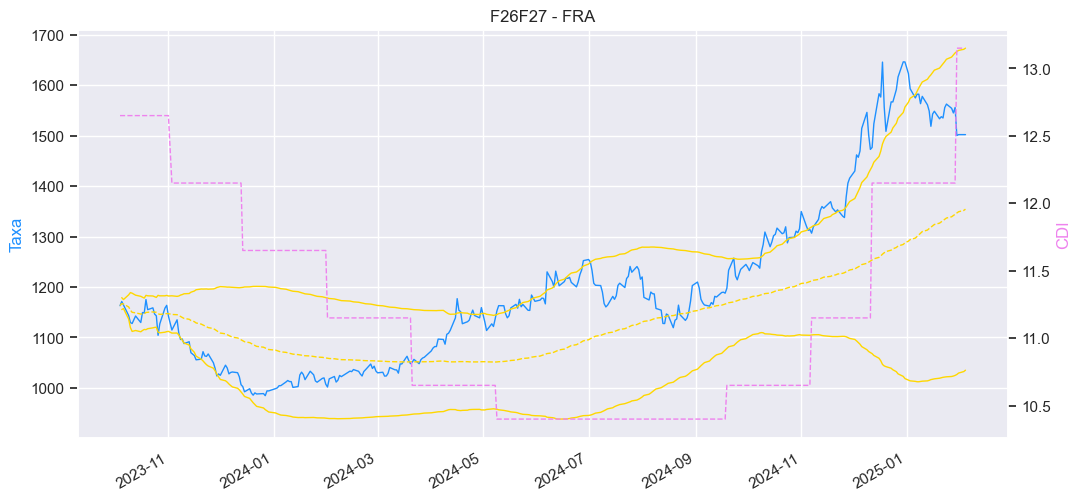

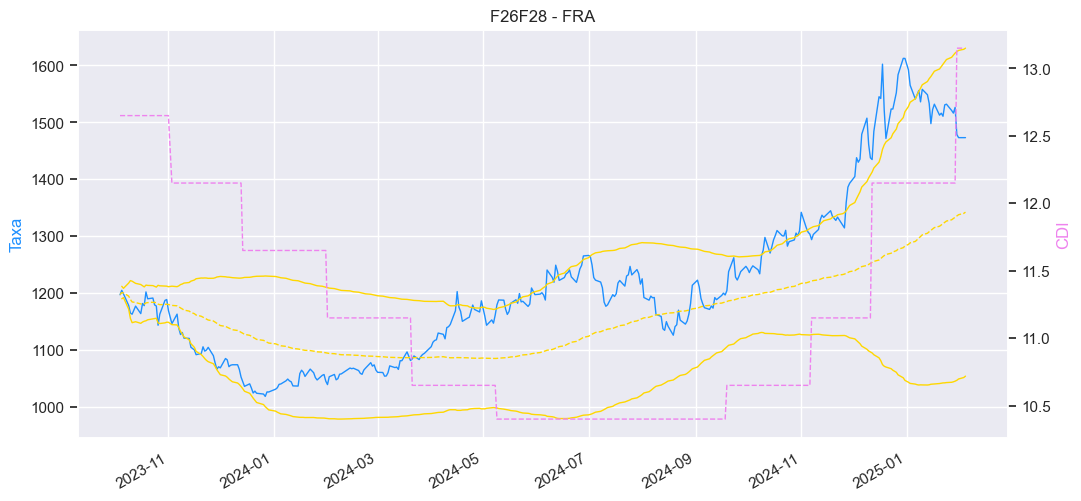

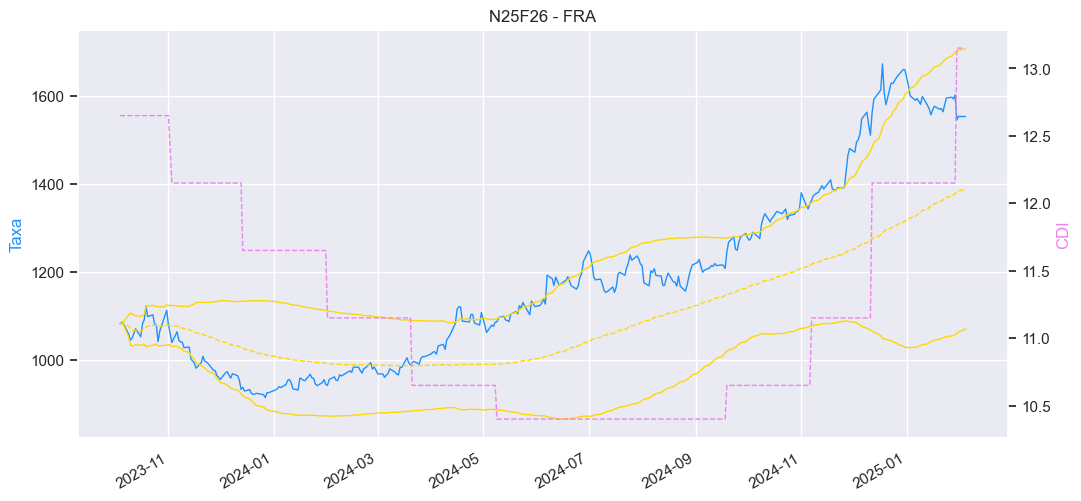

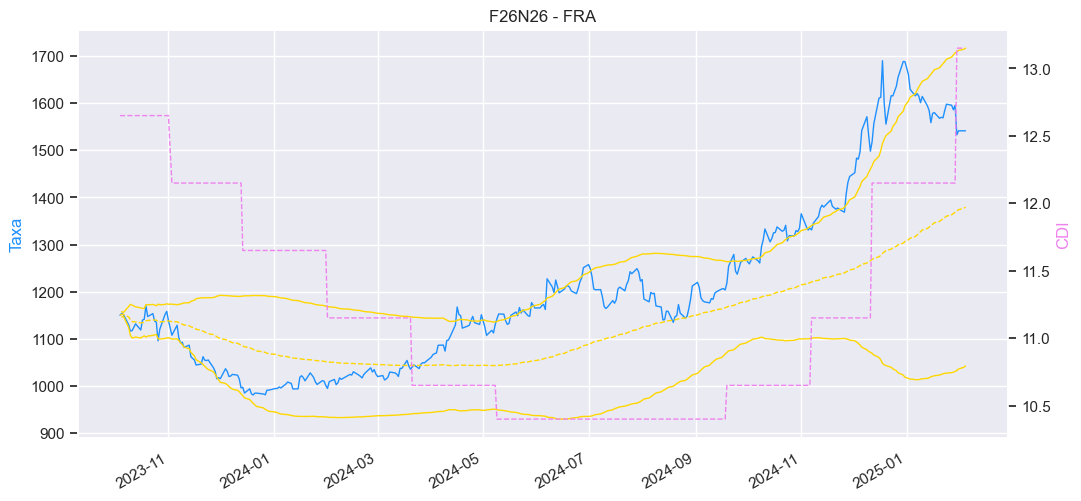

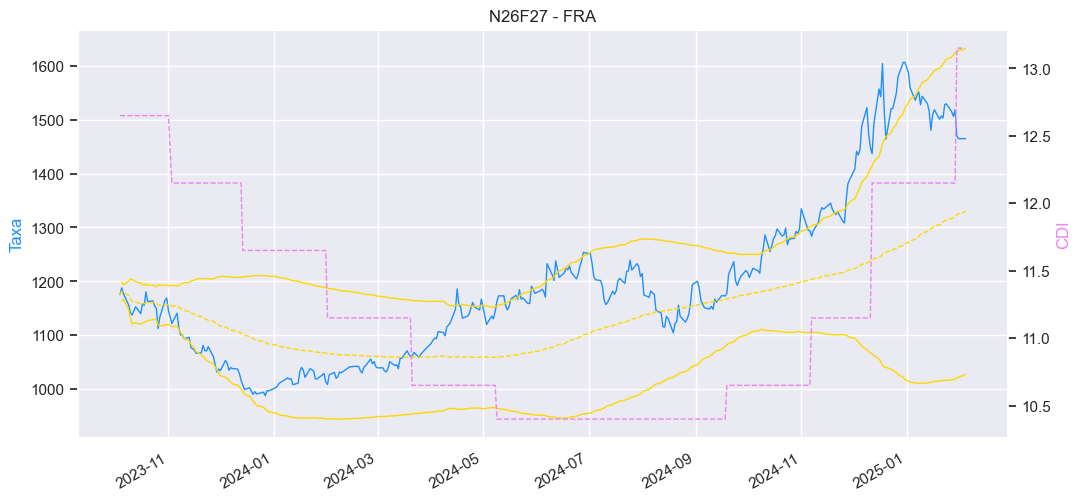

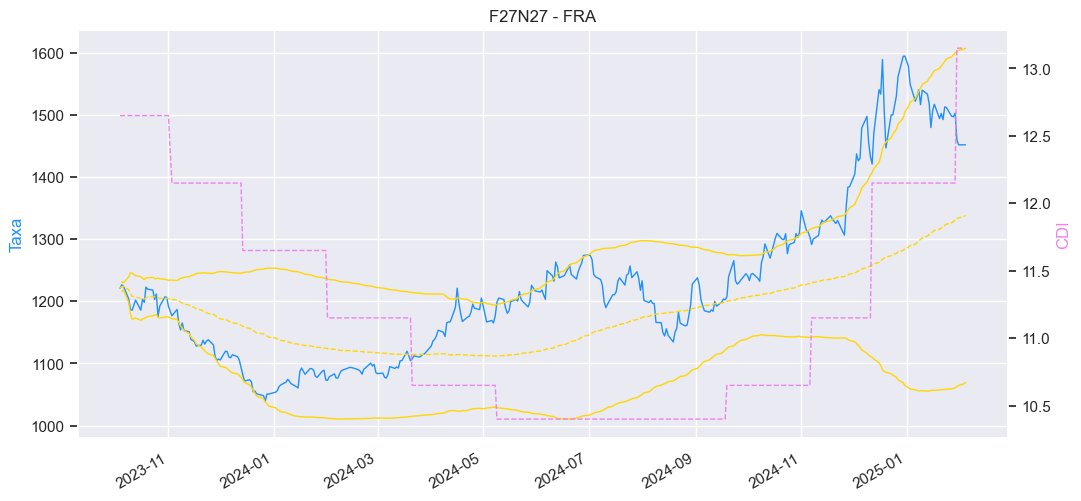

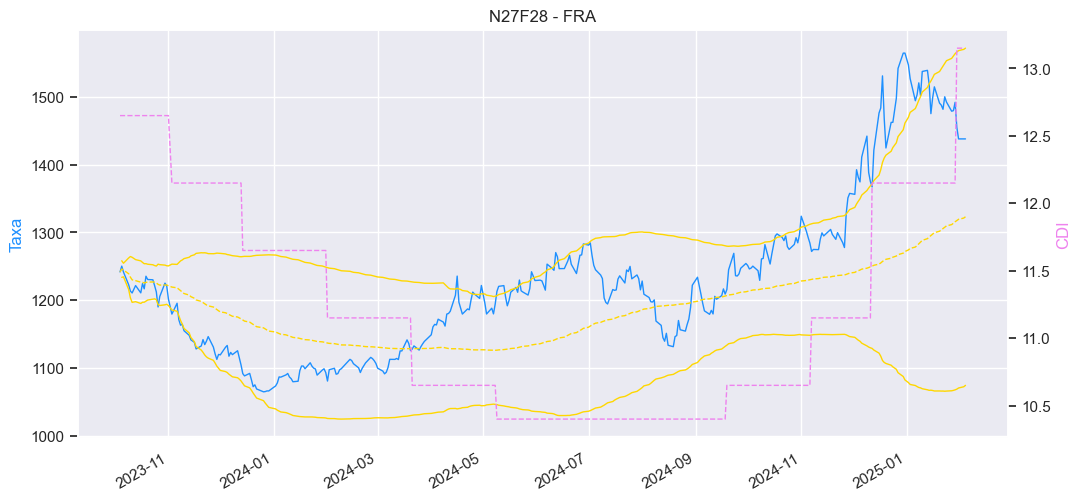

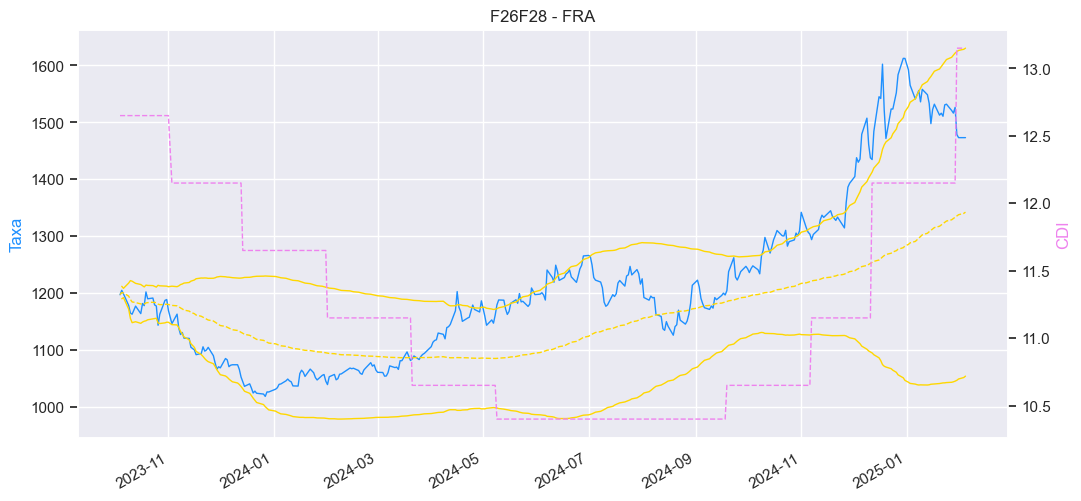

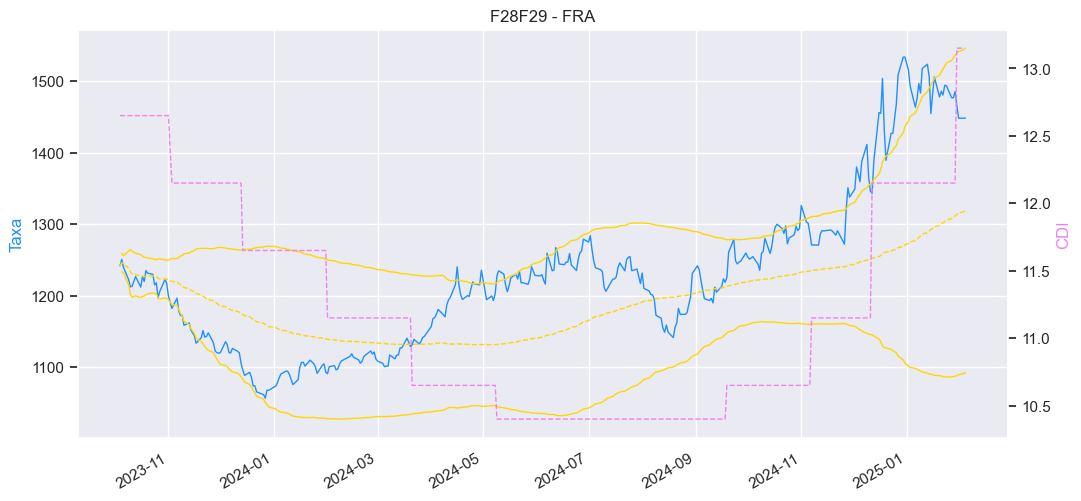

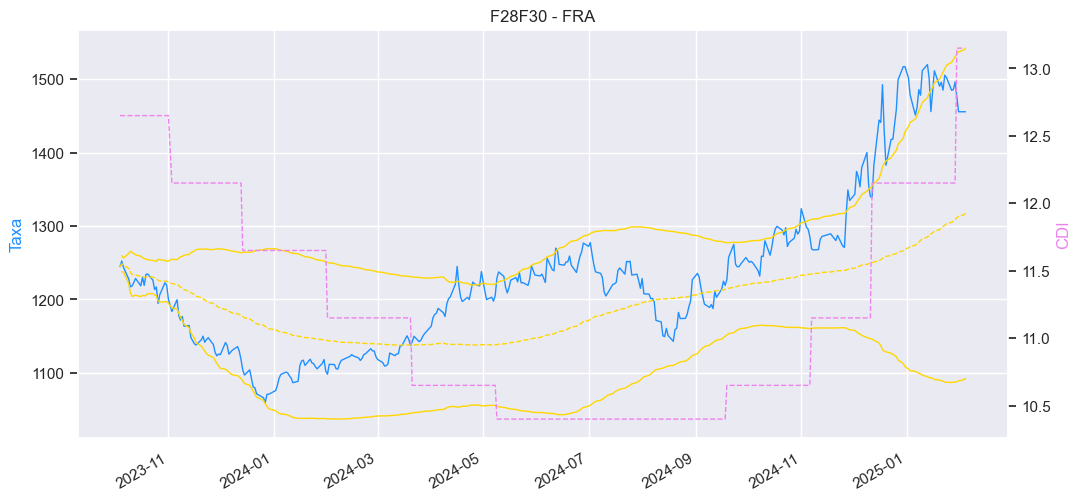

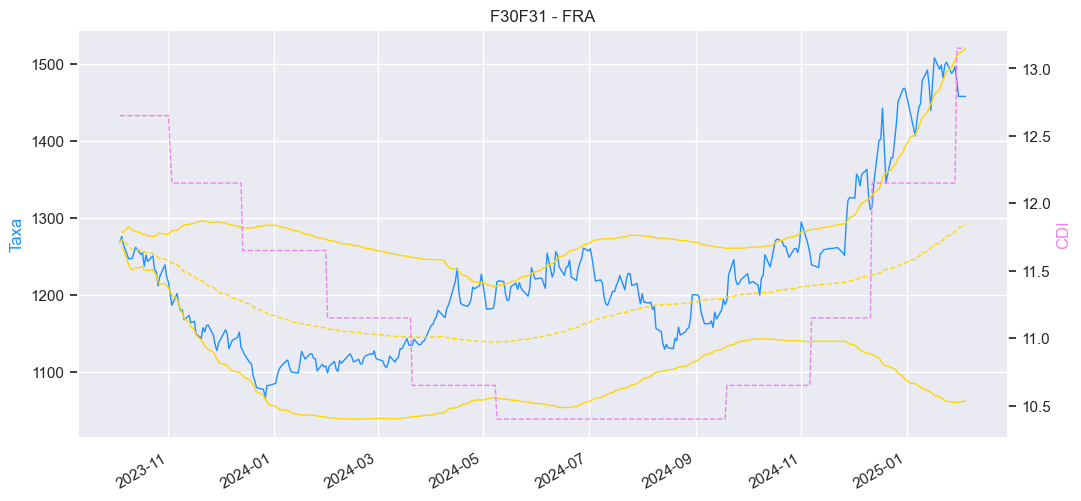

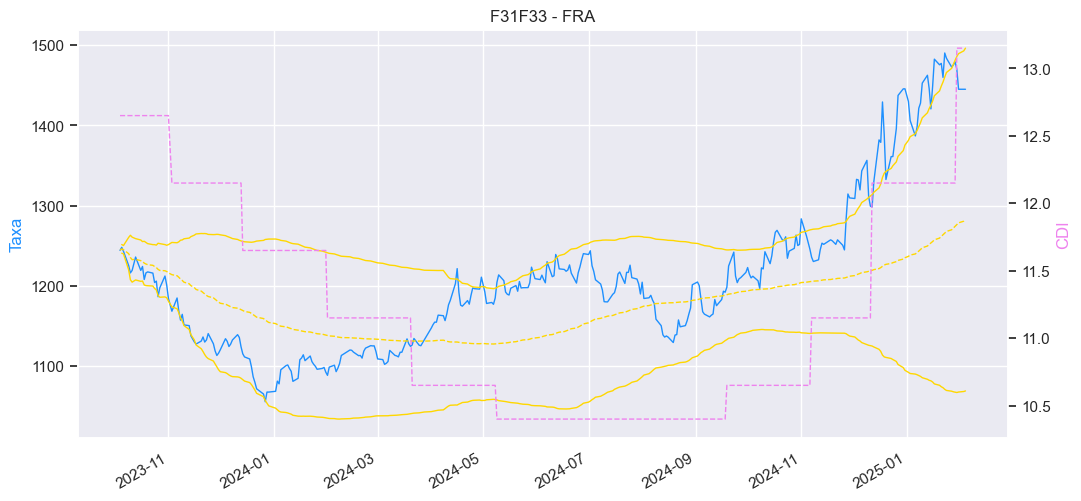

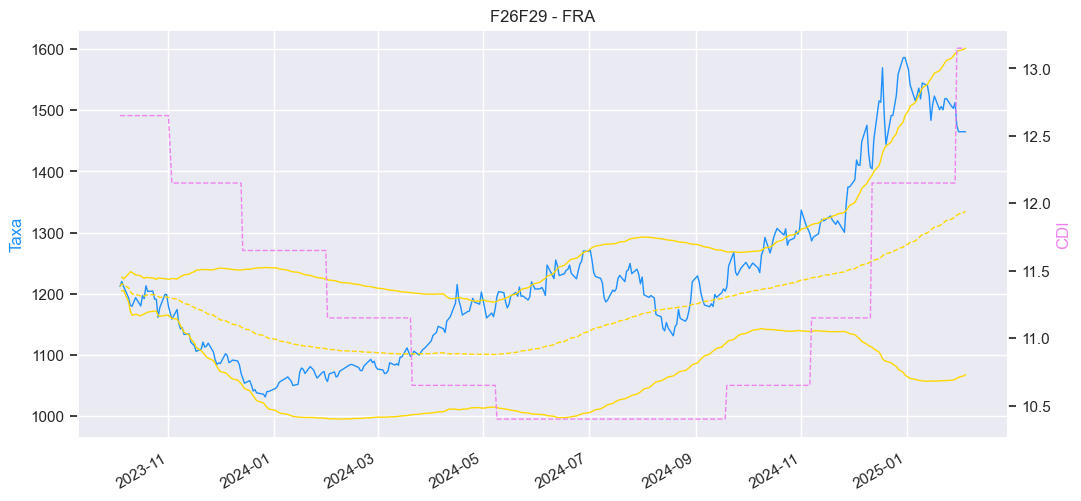

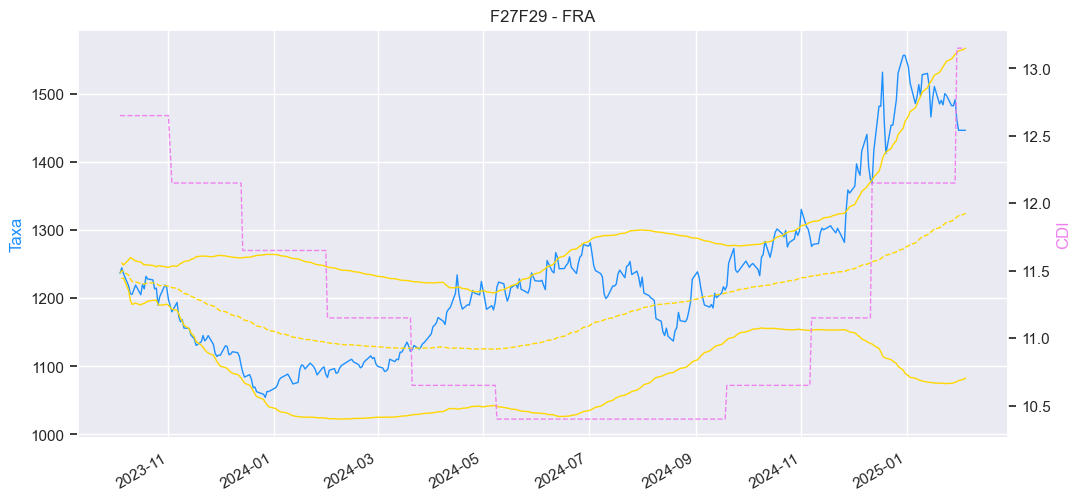

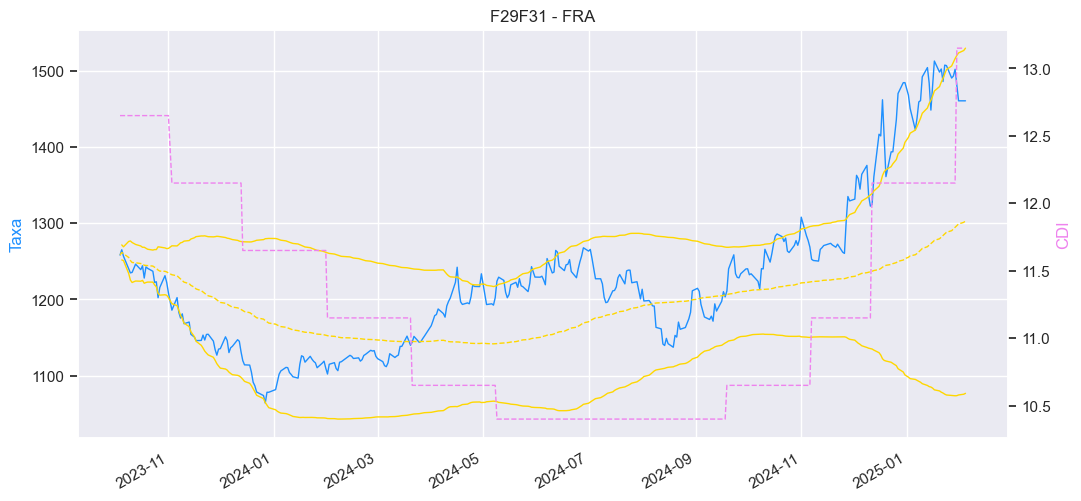

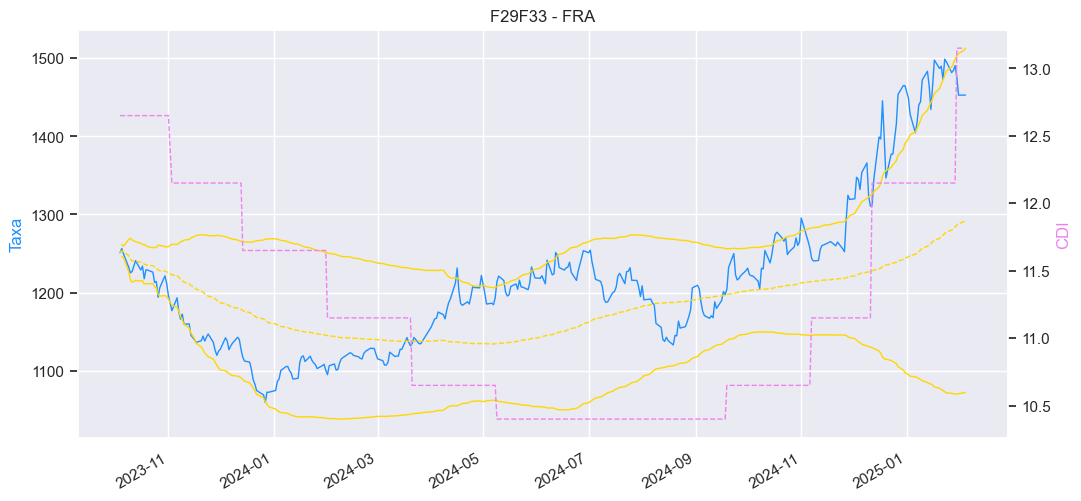

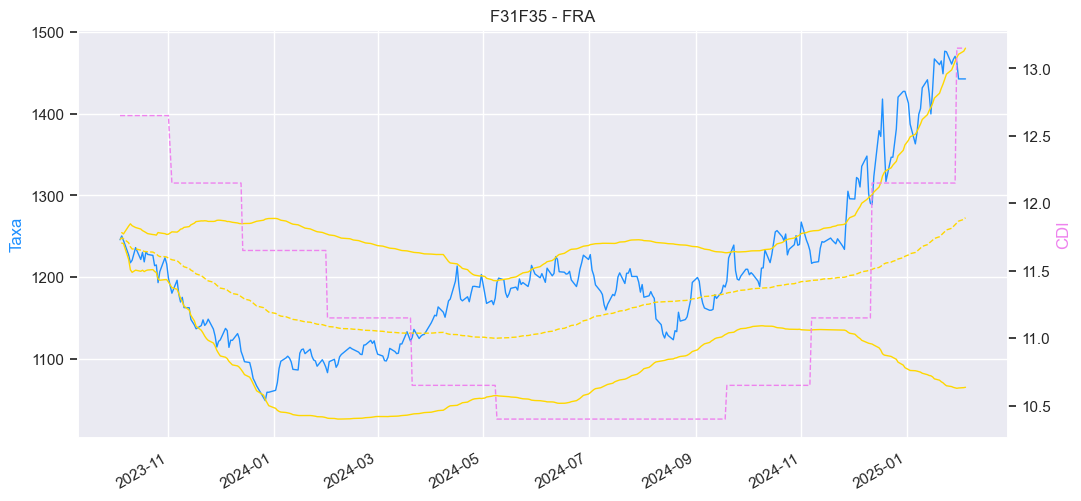

In [2]:
for x in lista: 
    df_grafico = df[df.VERTICES == x]
    df_grafico = df_grafico.sort_values(by=['DT'])
    nome = x

    sns.set(style="darkgrid", palette="Set2")
    plot.rcParams['figure.figsize'] = (12,6)

    fig, ax = plot.subplots()
    ax2 = ax.twinx()
    ax.plot(df_grafico.DT,df_grafico['TX_FRA']*10000, marker = '', color='dodgerblue',linestyle='-',linewidth=1,)
    ax.plot(df_grafico.DT,df_grafico['MEDIA_6M']*10000, marker='', color='gold',linestyle='--',linewidth=1)
    ax.plot(df_grafico.DT,df_grafico['LIM_INF_6M']*10000, marker='', color='gold',linestyle='-',linewidth=1)
    ax.plot(df_grafico.DT,df_grafico['LIM_SUP_6M']*10000, marker='', color='gold',linestyle='-',linewidth=1)
    ax2.plot(df_grafico.DT,df_grafico['CDI'], marker='', color='violet',linestyle='--',linewidth=1)
    ax.set_ylabel('Taxa', color='dodgerblue')
    ax2.set_ylabel('CDI', color='violet',labelpad=None)
    ax2.grid(visible=False)
    #ax.legend(loc='upper center')

    #ax.plot_date(fly_grafico.DT,fly_grafico['SUP_MDL']*10000, marker='', color='violet',linestyle='-',linewidth=1)
    #ax.plot_date(fly_grafico.DT,fly_grafico['INF_MDL']*10000, marker='', color='violet',linestyle='-',linewidth=1)
    plot.title(nome + " - FRA")
    #plot.ylabel('Taxa')
    plot.xlabel('Data')
    fig.autofmt_xdate()
    ax.fmt_xdata = mdates.DateFormatter('%Y-%m')
    plot.show()
    #plt.savefig('FLY.png', transparent = True)
    #fly_grafico.set_index('DT',inplace=True)

C:\Users\andre_trierveiler\AppData\Local\Temp\ipykernel_35940\2798499546.py:33: UserWarning:

pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.



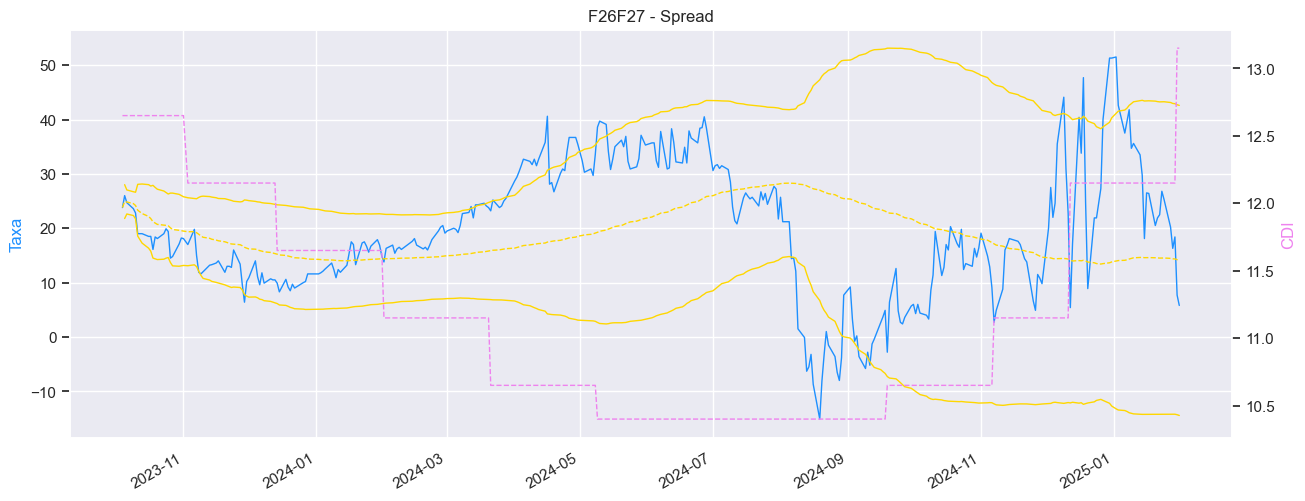

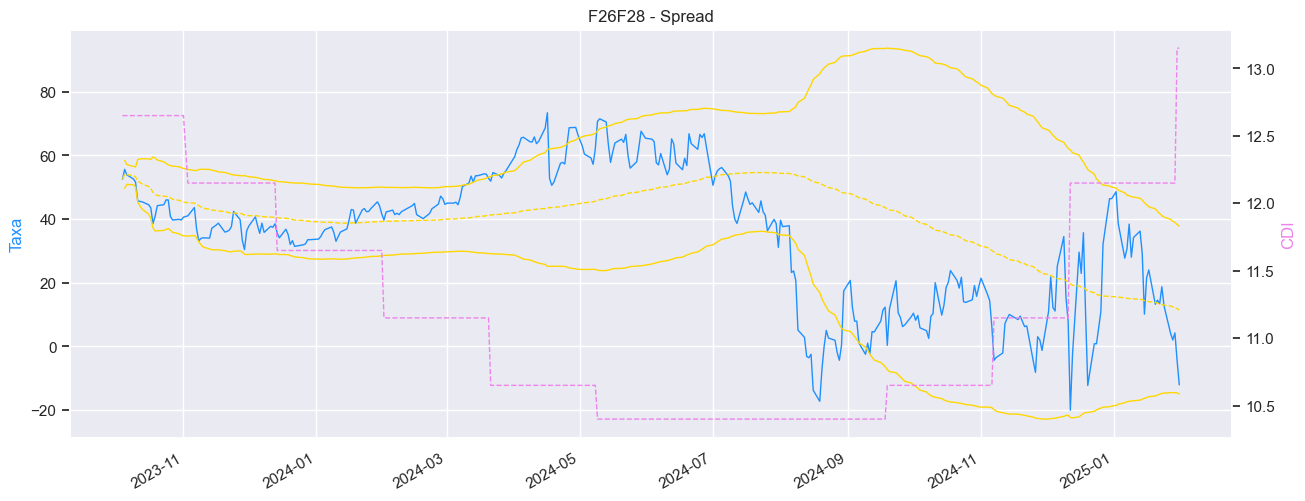

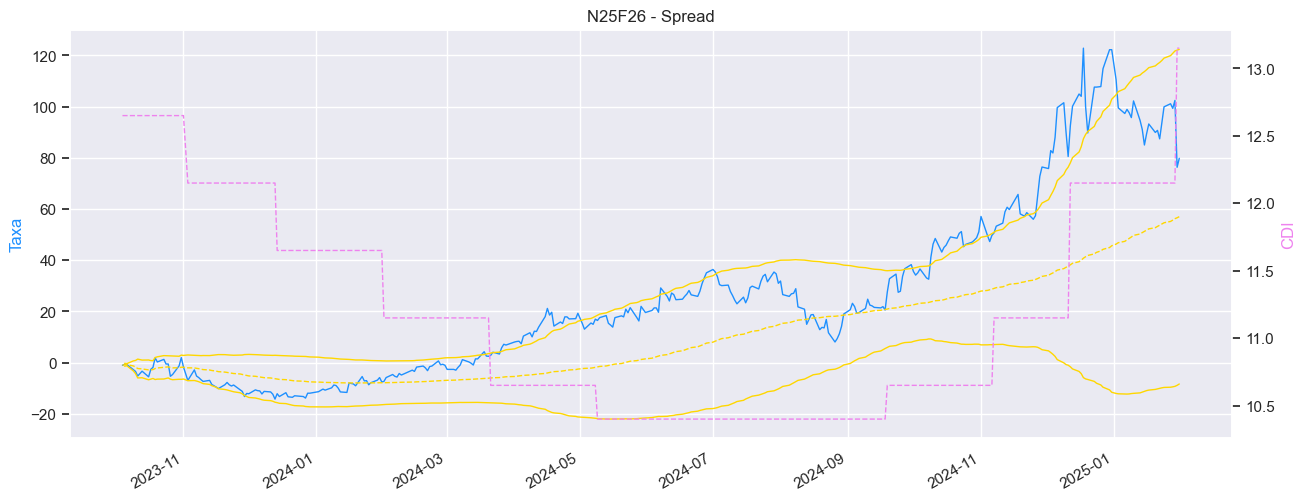

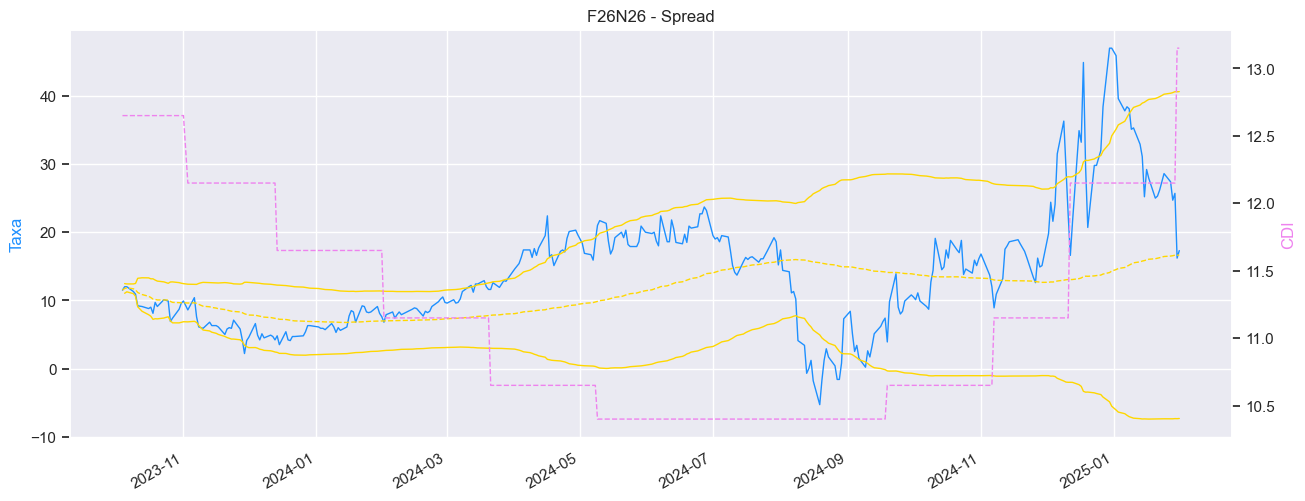

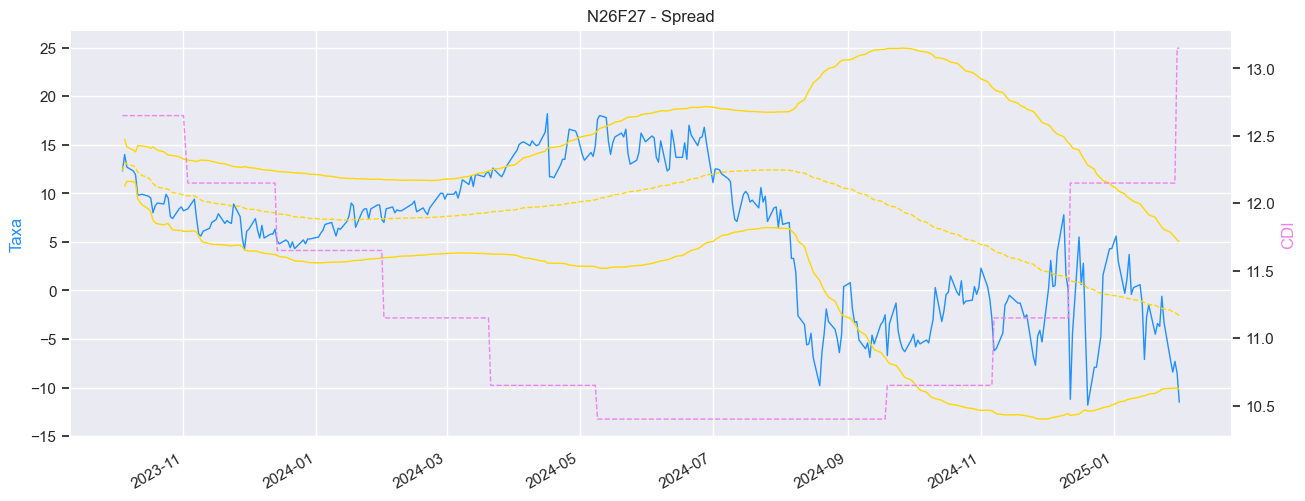

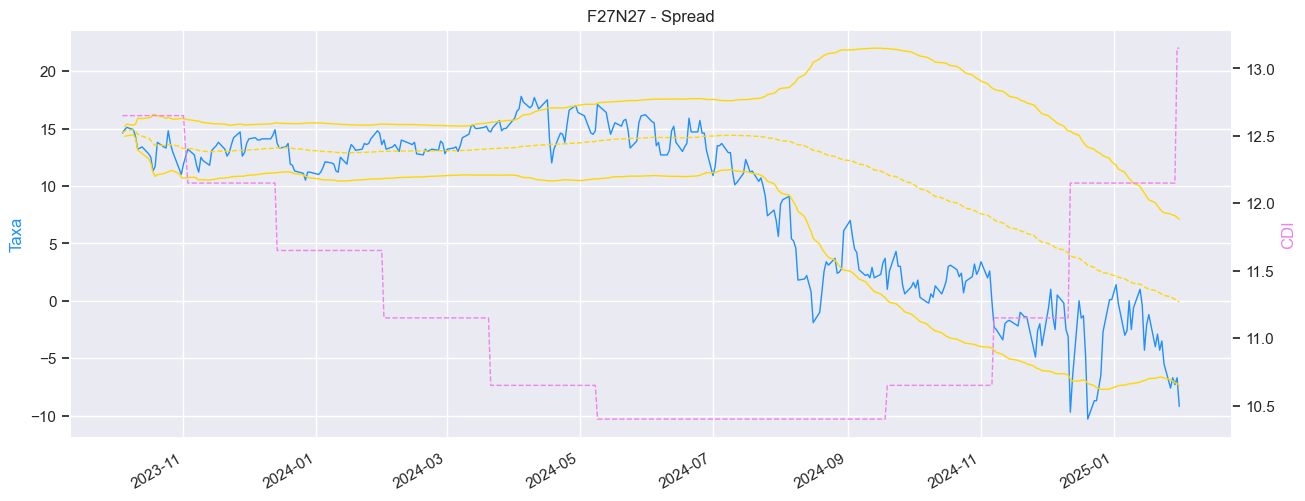

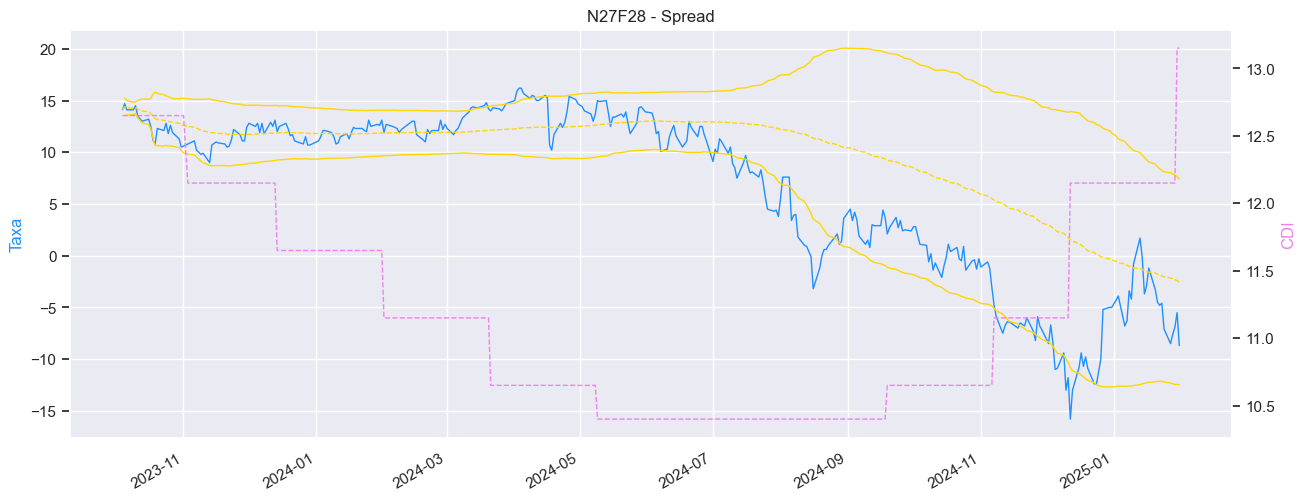

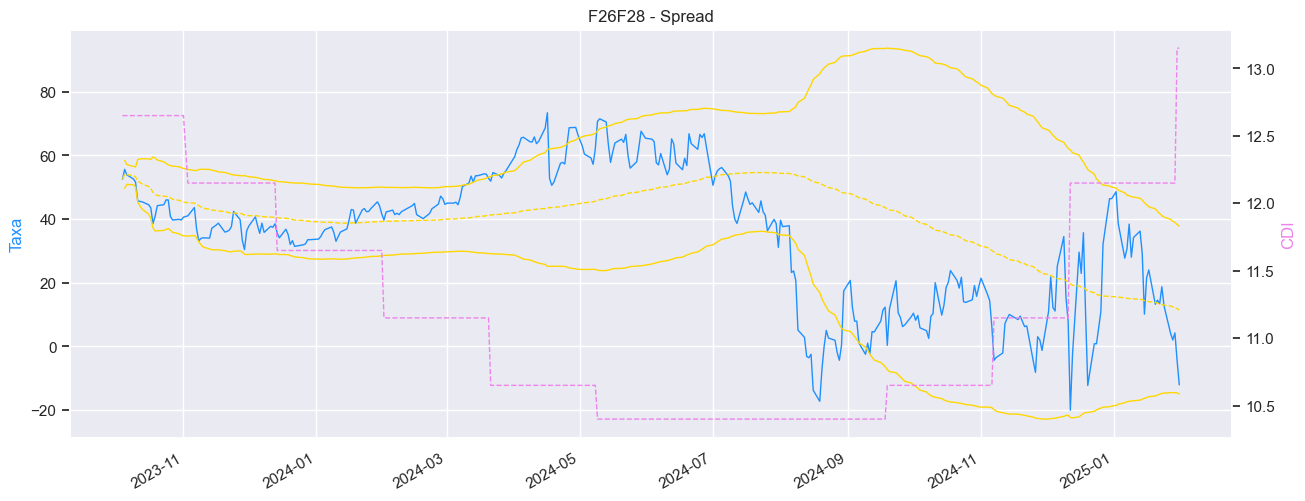

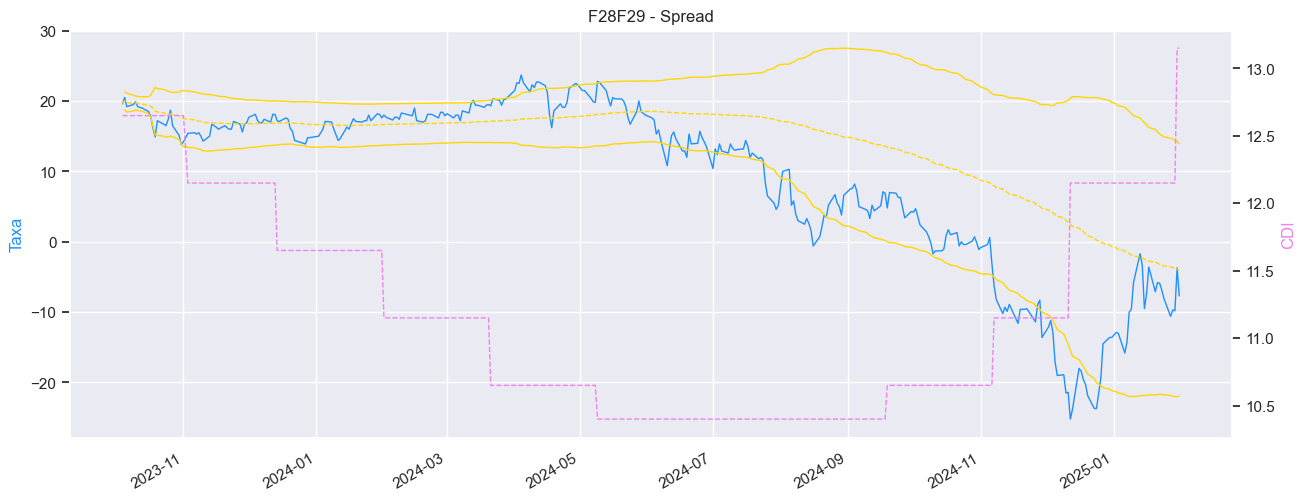

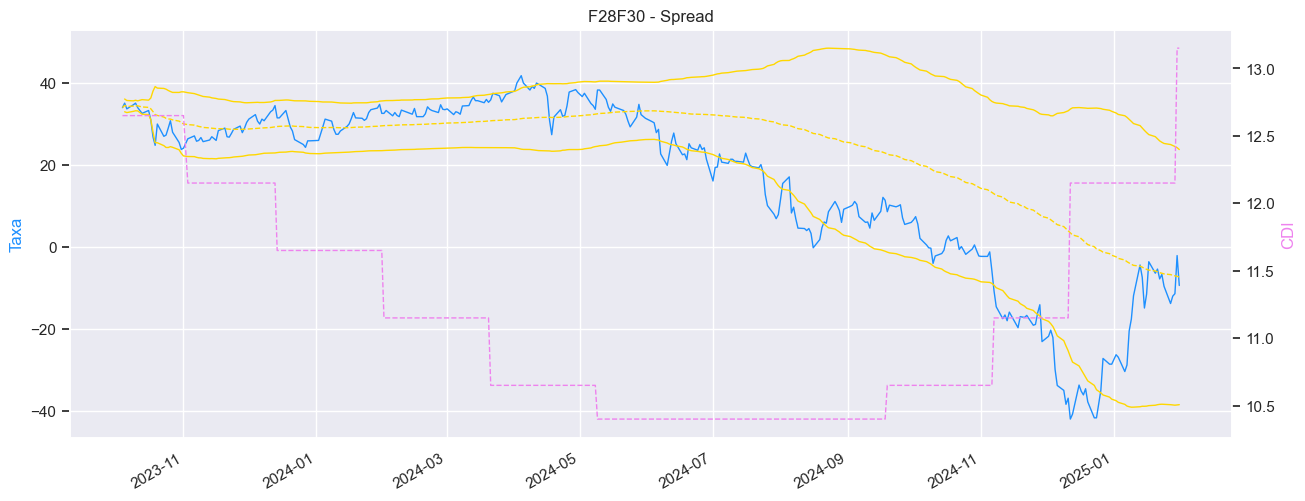

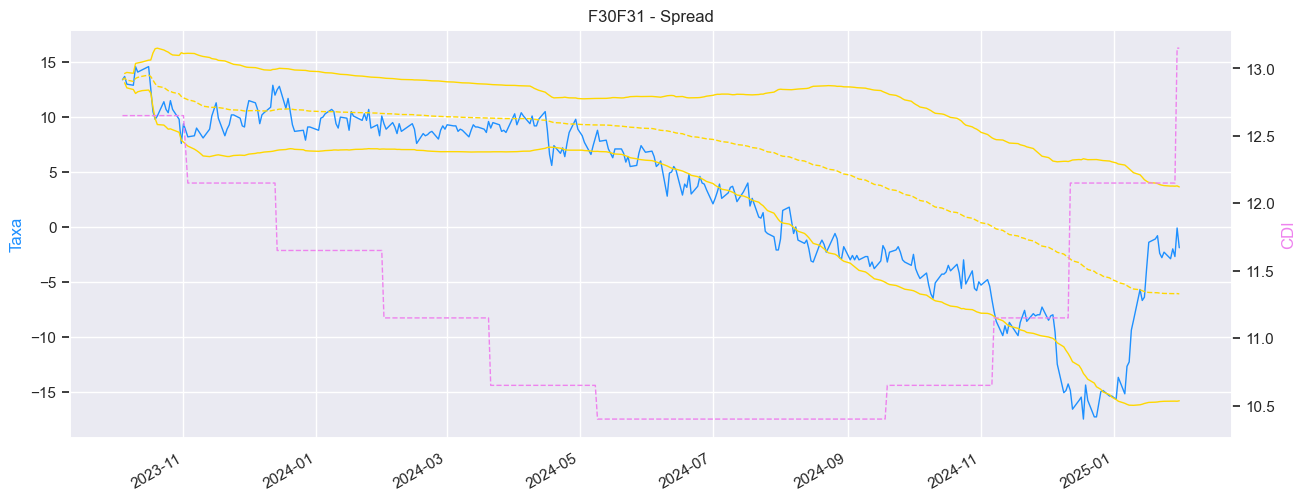

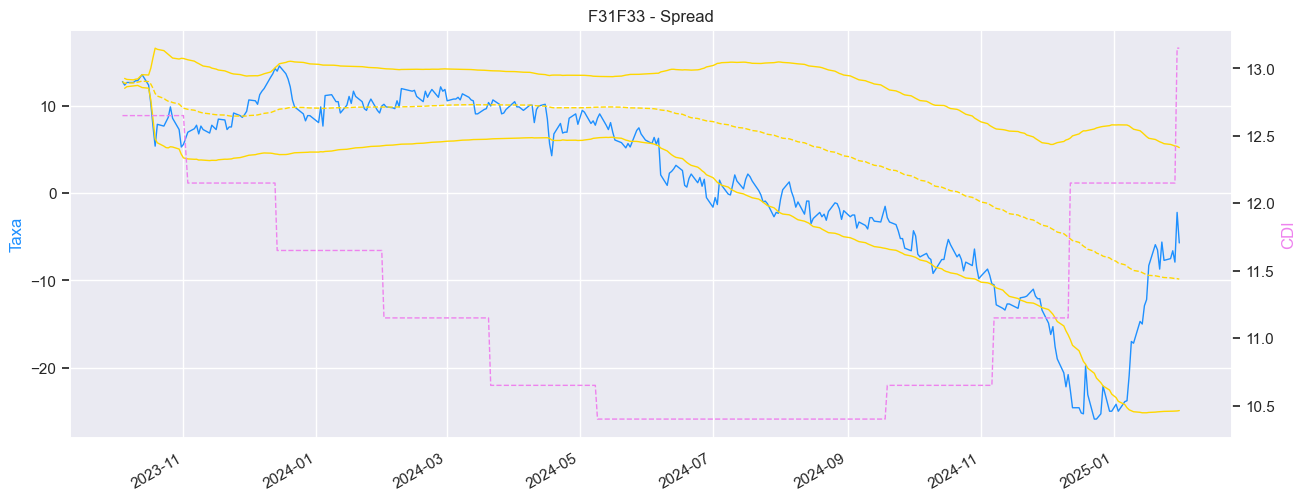

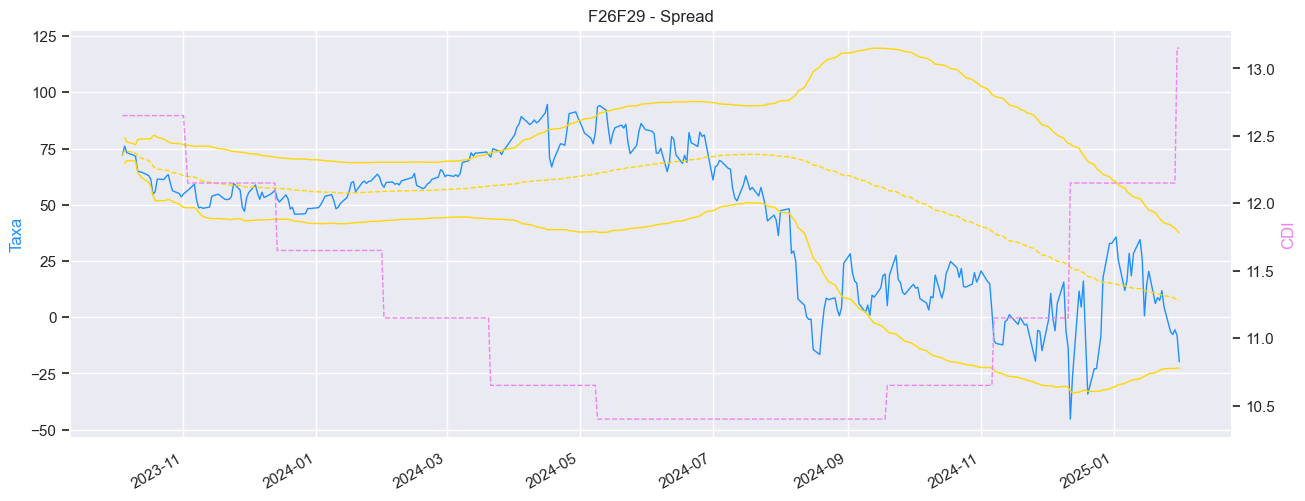

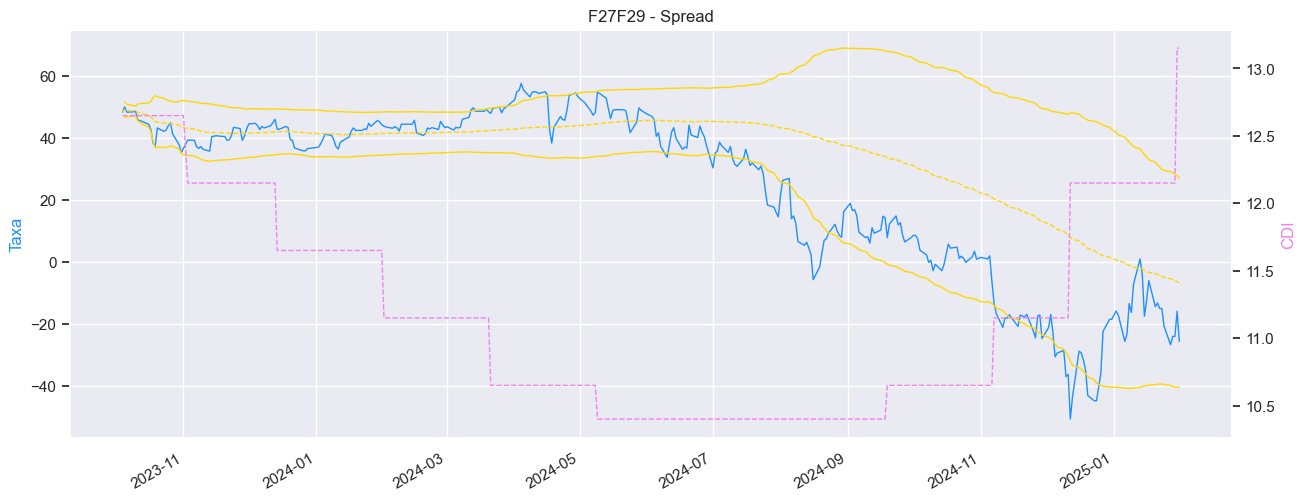

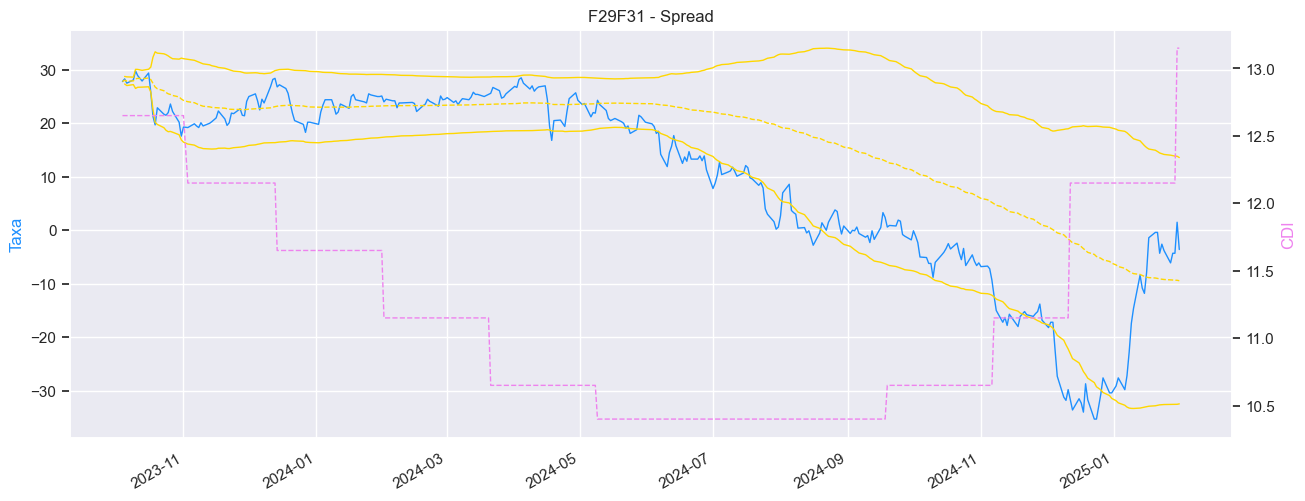

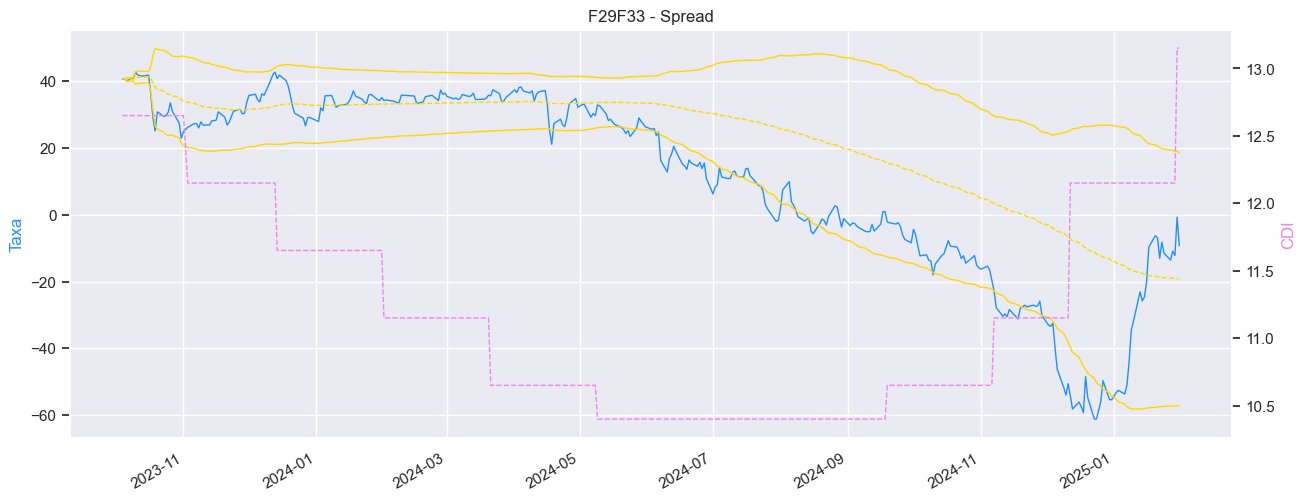

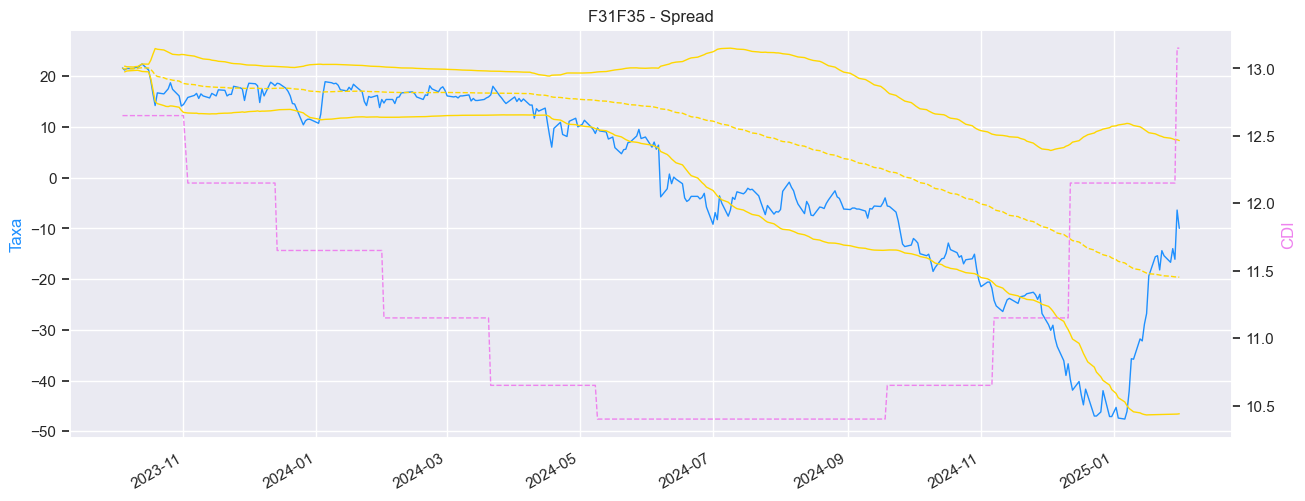

In [3]:
Select = f"""
SELECT FRA.DT
, FRA.FRA AS VERTICES
, FRA.TX_FRA
, FRA.TX_SPREAD
, AVG(FRA.TX_SPREAD) OVER (PARTITION BY FRA.FRA ORDER BY FRA.DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS MEDIA_6M
, AVG(FRA.TX_SPREAD) OVER (PARTITION BY FRA.FRA ORDER BY FRA.DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) + 2*(STDDEV_SAMP(FRA.TX_SPREAD) OVER (PARTITION BY FRA.FRA ORDER BY FRA.DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW)) as LIM_SUP_6M
, AVG(FRA.TX_SPREAD) OVER (PARTITION BY FRA.FRA ORDER BY FRA.DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) - 2*(STDDEV_SAMP(FRA.TX_SPREAD) OVER (PARTITION BY FRA.FRA ORDER BY FRA.DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW)) as LIM_INF_6M
, CDI
FROM
(SELECT DI_B.DT
, OREPLACE(DI_A.CONTRATO ||  DI_B.CONTRATO, 'DI1', '') AS FRA
, DI_A.CONTRATO AS CONTRATO_A, DI_B.CONTRATO AS CONTRATO_B
, DI_A.TAXA AS TAXA_A, DI_B.TAXA AS TAXA_B
, ((1+DI_B.TAXA)**(CAST(DI_B.DU AS FLOAT)/(DI_B.DU-DI_A.DU))/(1+DI_A.TAXA)**(CAST(DI_A.DU AS FLOAT)/(DI_B.DU-DI_A.DU)))-1 AS TX_FRA
,  (DI_B.TAXA - DI_A.TAXA) as TX_SPREAD
, 100000/((1+DI_A.TAXA+0.0001)**(CAST(DI_A.DU AS FLOAT)/252)) - 100000/((1+DI_A.TAXA)**(CAST(DI_A.DU AS FLOAT)/252)) as DIV01_A
, 100000/((1+DI_B.TAXA+0.0001)**(CAST(DI_B.DU AS FLOAT)/252)) - 100000/((1+DI_B.TAXA)**(CAST(DI_B.DU AS FLOAT)/252)) as DIV01_B
, ((IDX.VALOR/3000+1)**252.000000-1)*100 AS CDI

FROM DL_GESTAO_RECURSOS.VW_DI DI_B
LEFT JOIN DL_GESTAO_RECURSOS.VW_DI DI_A ON DI_A.DT = DI_B.DT AND DI_A.DU < DI_B.DU
LEFT JOIN DL_GESTAO_RECURSOS.DU ON DU.DT = DI_B.DT
LEFT JOIN DL_GESTAO_RECURSOS.IDX_INDEX IDX ON IDX.DATA = DI_B.DT AND IDX.CODINDEX = 'CDI'

WHERE DI_A.CONTRATO IS NOT NULL) FRA
WHERE FRA.DT between '{data_inicial}' and '{data_final}'
AND FRA IN ('{lista_string}')
"""
##AND FRA IN ('""" + lista_string +""" ') """


df = pd.read_sql(Select, session) 
df.DT = pd.to_datetime(df.DT, format='%Y-%m-%d')
   
pd.set_option('mode.chained_assignment', None)


for x in lista: 
    df_grafico = df[df.VERTICES == x]
    df_grafico = df_grafico.sort_values(by=['DT'])
    nome = x

    sns.set(style="darkgrid", palette="Set2")
    plot.rcParams['figure.figsize'] = (15,6)

    fig, ax = plot.subplots()
    ax2 = ax.twinx()
    ax.plot(df_grafico.DT,df_grafico['TX_SPREAD']*10000, marker = '', color='dodgerblue',linestyle='-',linewidth=1,)
    ax.plot(df_grafico.DT,df_grafico['MEDIA_6M']*10000, marker='', color='gold',linestyle='--',linewidth=1)
    ax.plot(df_grafico.DT,df_grafico['LIM_INF_6M']*10000, marker='', color='gold',linestyle='-',linewidth=1)
    ax.plot(df_grafico.DT,df_grafico['LIM_SUP_6M']*10000, marker='', color='gold',linestyle='-',linewidth=1)
    ax2.plot(df_grafico.DT,df_grafico['CDI'], marker='', color='violet',linestyle='--',linewidth=1)
    ax.set_ylabel('Taxa', color='dodgerblue')
    ax2.set_ylabel('CDI', color='violet',labelpad=None)
    ax2.grid(visible=False)
    #ax.legend(loc='upper center')

    #ax.plot_date(fly_grafico.DT,fly_grafico['SUP_MDL']*10000, marker='', color='violet',linestyle='-',linewidth=1)
    #ax.plot_date(fly_grafico.DT,fly_grafico['INF_MDL']*10000, marker='', color='violet',linestyle='-',linewidth=1)
    plot.title(nome + " - Spread")
    #plot.ylabel('Taxa')
    plot.xlabel('Data')
    fig.autofmt_xdate()
    ax.fmt_xdata = mdates.DateFormatter('%Y-%m')
    plot.show()
    #plt.savefig('FLY.png', transparent = True)
    #fly_grafico.set_index('DT',inplace=True)


C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.



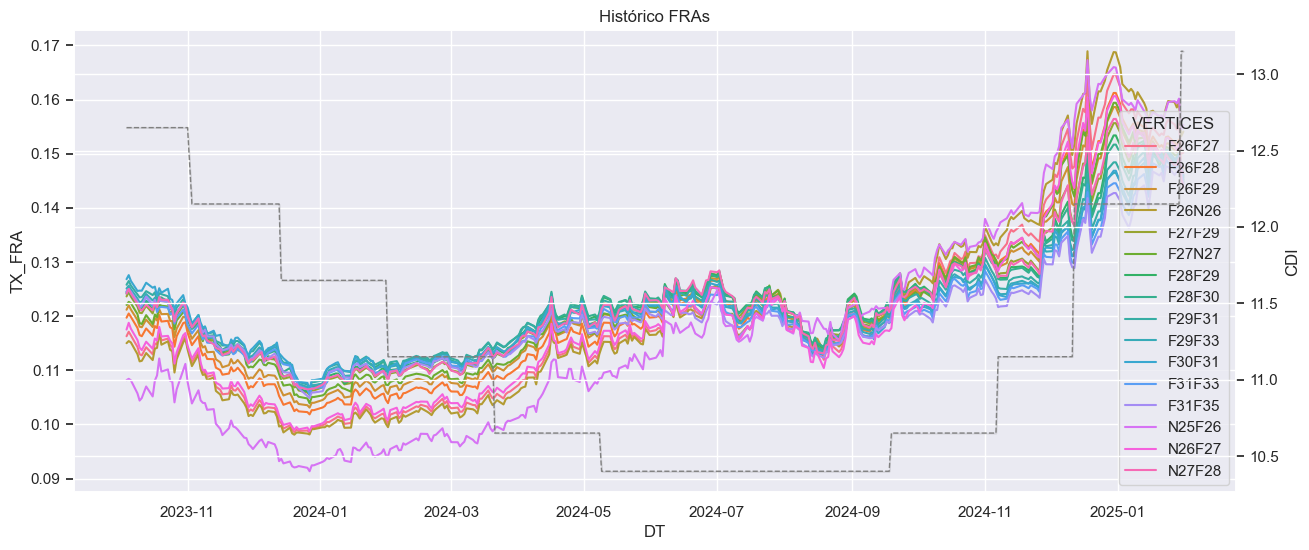

In [4]:
import matplotlib.pyplot as plot
df = df.sort_values(by=['DT','VERTICES'])
df_grafico  = df[df['VERTICES'].isin(lista)]

sns.set(style="darkgrid", palette="Set2")
ax1 = sns.lineplot(x='DT', y='TX_FRA', data=df_grafico, hue='VERTICES')
ax2 = ax1.twinx()
ax2 = sns.lineplot(x='DT', y='CDI', data=df_grafico, marker='', color='gray',linestyle='--',linewidth=1)
ax1.set(title='Histórico FRAs')
plot.show()

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.



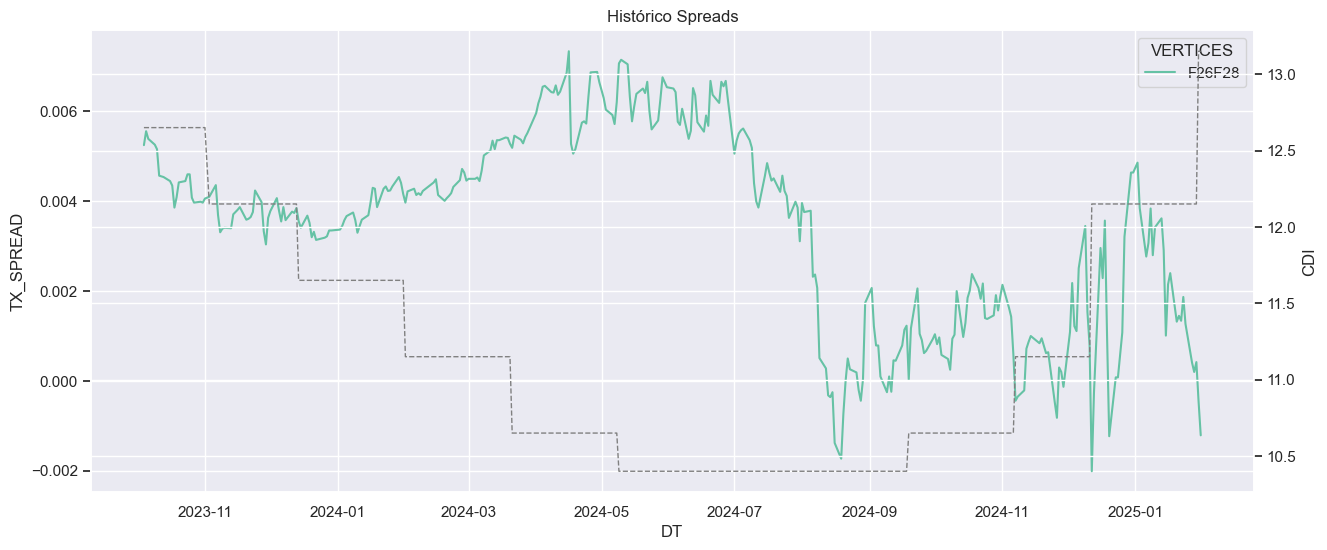

In [5]:
import matplotlib.pyplot as plot
df = df.sort_values(by=['DT','VERTICES'])
df_grafico  = df[df['VERTICES'].isin(['F24F27','F27F31','F27F33','F25F30','F27F32','F27F33','F25F27','F25F29','F26F28'])]

sns.set(style="darkgrid", palette="Set2")
ax1 = sns.lineplot(x='DT', y='TX_SPREAD', data=df_grafico, hue='VERTICES')
ax2 = ax1.twinx()
ax2 = sns.lineplot(x='DT', y='CDI', data=df_grafico, marker='', color='gray',linestyle='--',linewidth=1)
ax1.set(title='Histórico Spreads')
plot.show()